# EDA raw data in Bronze zone using Spark - Trino

- Import libraries and load environment files

In [1]:
import os

import matplotlib.pyplot as plt
from dotenv import load_dotenv
from pyspark.sql import DataFrame, SparkSession
from pyspark.sql import functions as F
from pyspark.sql import types as T

load_dotenv('../../../../.env_file/infra.env'), load_dotenv('../../../../.env_file/app.env')

(True, True)

- Download jar file to connect to Trino from Spark

In [17]:
!wget https://repo1.maven.org/maven2/io/trino/trino-jdbc/480/trino-jdbc-480.jar
!mv trino-jdbc-480.jar ../../../../spark/jar

--2026-08-07 08:51:30--  https://repo1.maven.org/maven2/io/trino/trino-jdbc/480/trino-jdbc-480.jar
Resolving repo1.maven.org (repo1.maven.org)... 104.18.18.12, 104.18.19.12, 2606:4700::6812:130c, ...
Connecting to repo1.maven.org (repo1.maven.org)|104.18.18.12|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 13104378 (12M) [application/java-archive]
Saving to: ‘trino-jdbc-480.jar’

trino-jdbc-480.jar    0%[                    ]       0  --.-KB/s               ^C


In [2]:
spark = (
    SparkSession.builder
    .appName('ingest data to silver zone')
    .config("spark.driver.memory", "8g")
    .config("spark.executor.memory", "8g")
    .config("spark.sql.session.timeZone", "UTC")
    # workaround for Spark 4.1.x CollapseProject optimizer bug
    .config("spark.sql.optimizer.excludedRules", "org.apache.spark.sql.catalyst.optimizer.CollapseProject")
    # delta lake support
    .config("spark.sql.extensions", "io.delta.sql.DeltaSparkSessionExtension")
    .config("spark.sql.catalog.spark_catalog", "org.apache.spark.sql.delta.catalog.DeltaCatalog")
    # read/write S3
    .config("spark.hadoop.fs.s3a.access.key", os.getenv('AWS_ACCESS_KEY_ID'))
    .config("spark.hadoop.fs.s3a.secret.key", os.getenv('AWS_SECRET_ACCESS_KEY'))
    # jar files supporting read/write postgres, trino, S3, hive (delta table for lake house)
    .config(
        'spark.jars',
        """
            ../../../../spark/jar/hadoop-aws-3.4.2.jar,
            ../../../../spark/jar/bundle-2.29.52.jar,
            ../../../../spark/jar/delta-spark_4.1_2.13-4.3.0.jar,
            ../../../../spark/jar/delta-kernel-api-4.3.0.jar,
            ../../../../spark/jar/delta-kernel-defaults-4.3.0.jar,
            ../../../../spark/jar/delta-storage-4.3.0.jar,
        """
    )
    # Hive metastore
    .config("spark.hadoop.hive.metastore.uris", "thrift://localhost:9084")
    # .config("spark.hadoop.hive.metastore.uris", fthrift://localhost:9084")
    .config("spark.sql.catalogImplementation", "hive")
    # create schema using spark (instead of using trino)
    .config("spark.sql.warehouse.dir", "s3a://nblong-data-project/nyc_taxi/warehouse/")
    .enableHiveSupport()
    .getOrCreate()
)

spark

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
26/08/11 16:14:45 WARN Utils: Your hostname, debian-nblong, resolves to a loopback address: 127.0.1.1; using 192.168.19.247 instead (on interface wlp0s20f3)
26/08/11 16:14:45 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address
26/08/11 16:14:46 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable
Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/08/11 16:14:47 WARN Utils: Service 'SparkUI' could not bind on port 4040. Attempting port 4041.
SLF4J: Failed to load class "org.slf4j.impl.StaticLoggerBinder".
SLF4J: Defaulting to no-operation (NOP) logger implementation
SLF4J: See http://www.slf4j.org/codes.html#StaticLoggerBinder for further details.


- Load data

In [3]:
df = spark.read.table('bronze.nyc_taxi')

## Thống kê mô tả

- Note: Tôi muốn EDA kỹ về dữ liệu, kéo nhiều bảng về hơn, chia dim-fact, múa SCD các thứ
- Note: Dim, fact, SCD chỉ áp dụng với serving layer (gold zone)

- Số dòng, số cột, tên cột

In [ ]:
df.count()

7059232

In [4]:
columns = df.columns
len(columns), columns

(33,
 ['vendor_id',
  'pickup_datetime',
  'dropoff_datetime',
  'passenger_count',
  'trip_distance',
  'rate_code_id',
  'store_and_fwd_flag',
  'pickup_longitude',
  'pickup_latitude',
  'dropoff_longitude',
  'dropoff_latitude',
  'pu_location_id',
  'do_location_id',
  'payment_type',
  'fare_amount',
  'extra',
  'mta_tax',
  'surcharge',
  'improvement_surcharge',
  'tip_amount',
  'tolls_amount',
  'total_amount',
  'congestion_surcharge',
  'airport_fee',
  'cbd_congestion_fee',
  'source_file',
  'source_created_datetime',
  'bronze_created_datetime',
  'year',
  'month',
  'day',
  'hour',
  'minute'])

- Kiểu dữ liệu từng cột

In [4]:
df.dtypes

[('vendor_id', 'string'),
 ('pickup_datetime', 'timestamp'),
 ('dropoff_datetime', 'timestamp'),
 ('passenger_count', 'double'),
 ('trip_distance', 'double'),
 ('rate_code_id', 'double'),
 ('store_and_fwd_flag', 'string'),
 ('pickup_longitude', 'double'),
 ('pickup_latitude', 'double'),
 ('dropoff_longitude', 'double'),
 ('dropoff_latitude', 'double'),
 ('pu_location_id', 'string'),
 ('do_location_id', 'string'),
 ('payment_type', 'string'),
 ('fare_amount', 'double'),
 ('extra', 'double'),
 ('mta_tax', 'double'),
 ('surcharge', 'double'),
 ('improvement_surcharge', 'double'),
 ('tip_amount', 'double'),
 ('tolls_amount', 'double'),
 ('total_amount', 'double'),
 ('congestion_surcharge', 'double'),
 ('airport_fee', 'double'),
 ('cbd_congestion_fee', 'double'),
 ('source_file', 'string'),
 ('source_created_datetime', 'timestamp'),
 ('record_key', 'string'),
 ('bronze_created_datetime', 'timestamp'),
 ('year', 'int'),
 ('month', 'int')]

- Ý nghĩa từng cột ([ref](https://www.nyc.gov/assets/tlc/downloads/pdf/data_dictionary_trip_records_yellow.pdf)) và kiểu dữ liệu tương ứng trong bronze zone hiện tại
    1. `vendor_id (string)`: ID của vendor cung cấp các công nghệ cho xe (rooftop sign, a taximeter, and a backseat Passenger Information Monitor)
        - 1: Creative Mobile Technologies, LLC
        - 2: Curb Mobility, LLC
        - 6: Myle Technologies Inc
        - 7: Helix
    2. `pickup_datetime (timestamp)`: Giờ đón khách (tính từ lúc taximeter được bật)
    3. `dropoff_datetime (timestamp)`: Giờ trả khách (tính từ lúc taximeter được tắt)
    4. `passenger_count (double)`: Số hành khách $\to$ `int`
    5. `trip_distance (double)`: Quãng đường (mile) được tính trên taximeter
    6. `rate_code_id (double)`: Xác định loại giá áp dụng cho chuyến đi $\to$ `string`
        - 1: Standard rate
        - 2: JFK
        - 3: Newark
        - 4: Nassau or Westchester
        - 5: Negotiated fare
        - 6: Group ride
        - 99: Null/unknown
    7. `store_and_fwd_flag (string)`: Cho biết liệu trip-record có được lưu trên xe trước khi gửi hay không
        - Y: Store and forward trip
        - N: Not a store and forward trip
    8. `pickup_longitude (double)`: Kinh độ điểm đón
    9. `pickup_latitude (double)`: Vĩ độ điểm đón
    10. `dropoff_longitude (double)`: Kinh độ điểm trả
    11. `dropoff_latitude (double)`: Vĩ độ điểm trả
    12. `pu_location_id (string)`: Mã khu vực đón khách (lúc taximeter được bật) $\to$ `int`
    13. `do_location_id (string)`: Mã khu vực trả khách (lúc taximeter được tắt) $\to$ `int`
    14. `payment_type (string)`: Phương thức thanh toán $\to$ `string`
        - 0: Flex Fare trip
        - 1: Credit card
        - 2: Cash
        - 3: No charge
        - 4: Dispute
        - 5: Unknown
        - 6: Voided trip
    15. `fare_amount (double)`: Cước phí tính theo taximeter
    16. `extra (double)`: Phí phát sinh và surcharge (phụ phí)
    17. `mta_tax (double)`: Thuế tính trên quãng đường đã đi
    18. `surcharge (double)`: Phụ phí
    19. `improvement_surcharge (double)`: Phụ phí cải thiện (tôi không rõ nó là gì), được áp dụng từ 2015
    20. `tip_amount (double)`: Tiền tip bằng thẻ tín dụng
    21. `tolls_amount (double)`: Phí cầu đường
    22. `total_amount (double)`: Tổng tiền cho một chuyến đi, không bao gồm tiền tip
    23. `congestion_surcharge (double)`: Tổng phụ phí tắc đường
    24. `airport_fee (double)`: Đón tại LaGuardia và John F. Kennedy Airports thì cần phí này
    25. `cbd_congestion_fee (double)`: Phí tính cho khu giảm tắc nghẽn (từ Jan 5, 2025)
    26. `year (int)`: Năm, tách ra từ `pickup_datetime`
    27. `month (int)`: Tháng, tách ra từ `pickup_datetime`

- Đây là mô tả dữ liệu cho thời điểm mới nhất (May 2026). Tại các thời điểm trong quá khứ, có thể sẽ không follow theo chuẩn này. Tôi sẽ thay thế giá trị int của những cột category thành giá trị string chuẩn, đồng thời ép kiểu một số cột như đã note ở trên

- Cast `passenger_count`, `pu_location_id`, `do_location_id` to `int`

In [6]:
cast_map = {
    'passenger_count': F.col('passenger_count').cast(T.IntegerType()),
    'pu_location_id' : F.col('pu_location_id').cast(T.IntegerType()),
    'do_location_id' : F.col('do_location_id').cast(T.IntegerType()),
    'rate_code_id'   : F.col('rate_code_id').cast(T.IntegerType()),
}
preprocessed_df = df.withColumns(cast_map)

- Update `payment_type`, `rate_code_id`, `store_and_fwd_flag`, `vendor_id`

- Update `payment_type`: value_count trước, sau đó create mapping và replace

In [5]:
def value_counts(df:DataFrame, col:str) -> DataFrame:
    return df.groupBy(col).count().orderBy('count')

In [11]:
value_counts(df, 'rate_code_id').show()

+------------+-------+
|rate_code_id|  count|
+------------+-------+
|        11.0|      1|
|        34.0|      1|
|         8.0|      2|
|       128.0|      5|
|        35.0|     10|
|        24.0|     10|
|         6.0|     11|
|        33.0|     13|
|        16.0|     24|
|         0.0|    199|
|         5.0|    553|
|         4.0|   1337|
|         3.0|   2197|
|         2.0|   3695|
|         1.0| 550445|
|        NULL|1674953|
+------------+-------+



In [ ]:
rate_code_id_map = {
    "1.0": "Standard rate",
    "2.0": "JFK",
    "3.0": "Newark",
    "4.0": "Nassau or Westchester",
    "5.0": "Negotiated fare",
    "6.0": "Group ride",
    "99.0": "Null/unknown",
}
bla = (
    df.filter(
        ((F.col('rate_code_id')>=1) & (F.col('rate_code_id')<=6)) | (F.col('rate_code_id')==99) |
        (F.col('rate_code_id').isNull())
    )
    .withColumn('rate_code_id', F.col('rate_code_id').cast('string'))
    .replace(rate_code_id_map, subset='rate_code_id')
    .withColumnRenamed('rate_code_id', 'rate_code')
)

value_counts(bla, 'rate_code_id').show()

+--------------------+-------+
|        rate_code_id|  count|
+--------------------+-------+
|          Group ride|     11|
|     Negotiated fare|    553|
|Nassau or Westche...|   1337|
|              Newark|   2197|
|                 JFK|   3695|
|       Standard rate| 550445|
|                NULL|1674953|
+--------------------+-------+



PySparkValueError: [MIXED_TYPE_REPLACEMENT] Mixed type replacements are not supported.

In [6]:
value_counts(df, 'rate_code_id').show()

26/08/11 16:24:22 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.


+------------+-------+
|rate_code_id|  count|
+------------+-------+
|        11.0|      1|
|        34.0|      1|
|         8.0|      2|
|       128.0|      5|
|        35.0|     10|
|        24.0|     10|
|         6.0|     11|
|        33.0|     13|
|        16.0|     24|
|         0.0|    199|
|         5.0|    553|
|         4.0|   1337|
|         3.0|   2197|
|         2.0|   3695|
|         1.0| 550445|
|        NULL|1674953|
+------------+-------+



In [ ]:
df_paymentType = preprocessed_df.withColumn('payment_type_id', F.lower(F.trim(F.col('payment_type'))))

# value count
value_counts(df_paymentType, 'payment_type_id').show()

+------------+-------+
|payment_type|  count|
+------------+-------+
|           4|      2|
|           3|      7|
|           5|     10|
|         noc|    318|
|         dis|    491|
|          na|    527|
|     dispute|    881|
|          no|   1934|
|   no charge|   4911|
|         cre| 296771|
|         crd| 313851|
|      credit| 440242|
|         csh| 512735|
|         cas| 548452|
|           1| 855591|
|           2|1097879|
|        cash|1228919|
+------------+-------+



In [ ]:
# mapping
payment_map = {
    # "0": "Flex Fare trip",

    # Cash
    'cash': '2',
    "cas": "2",
    "csh": "2",
    # "2": "Cash",

    # Credit card
    "credit": "1",
    "crd": "1",
    "cre": "1",
    "1": "1",

    # No charge
    "no charge": "3",
    "no": "3",
    "noc": "3",
    # "3": "No charge",

    # Dispute
    "dispute": "4",
    "dis": "4",
    # "4": "Dispute",

    # Unknown
    "na": "5",
    # "5": "Unknown",

    # "6": "Voided trip",
}

# replace
preprocessed_df = df_paymentType.replace(payment_map, subset='payment_type_id')
preprocessed_df = preprocessed_df.withColumn('payment_type_id', F.col('payment_type_id').cast("int"))
preprocessed_df = preprocessed_df.drop('payment_type')
value_counts(preprocessed_df, 'payment_type_id').show()

+------------+-------+
|payment_type|  count|
+------------+-------+
|           5|    537|
|           4|   1374|
|           3|   7170|
|           1|1906455|
|           2|3387985|
+------------+-------+



- Check `passenger_count`. Đang có vài value không phù hợp
    - Những value quá lớn: Drop hết
    - Value=0: Cần ingest cái này

In [7]:
value_counts(preprocessed_df, 'passenger_count').show()

26/08/07 10:44:43 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.


+---------------+-------+
|passenger_count|  count|
+---------------+-------+
|            250|      1|
|             49|      2|
|            208|      9|
|              0|  30355|
|              6|  34084|
|              4| 116579|
|              3| 240245|
|              5| 436820|
|              2| 832692|
|              1|3612734|
+---------------+-------+



In [8]:
# filter those having count < 7
preprocessed_df = preprocessed_df.filter(F.col('passenger_count')<7)

In [9]:
# check those having count=0
df_pc = (
    preprocessed_df.filter(F.col('passenger_count')==0)
    .select(
        F.col('dropoff_longitude')-F.col('pickup_longitude'),
        F.col('dropoff_latitude')-F.col('pickup_latitude'),
        'payment_type',
        'fare_amount',
        'tip_amount'
    )
)

- Số lượng `NULL` về chênh lệch toạ độ khoảng 98%

In [11]:
count = df_pc.count()
for col in df_pc.columns:
    print(f'%missing of {col}: {df_pc.filter(F.col(col).isNull()).count()/count}')
    print('===')

%missing of (dropoff_longitude - pickup_longitude): 0.9875144127820787
===


%missing of (dropoff_latitude - pickup_latitude): 0.9875144127820787
===
%missing of payment_type: 0.0
===
%missing of fare_amount: 0.0
===
%missing of tip_amount: 0.0
===


- Trong số 2% chứa dữ liệu không NULL, có đến 98% chênh lệch toạ độ quá nhỏ (<1.5)

In [12]:
df_pc.filter(
    (F.col('(dropoff_longitude - pickup_longitude)')<1.5) &
    (F.col('(dropoff_latitude - pickup_latitude)')<1.5)
).count()/(count*(1-0.9875144127820787))

0.9841688654353568

- Kết luận: Dữ liệu tầm bậy, không có khách, di chuyển tầm bậy, số tiền chỉ là input linh tinh. Tóm lại là tôi sẽ xoá hết mớ data có `passenger_count=0`

In [64]:
preprocessed_df = preprocessed_df.filter(
    F.col('passenger_count')!=0
)
value_counts(preprocessed_df, 'passenger_count').show()

+---------------+-------+
|passenger_count|  count|
+---------------+-------+
|              6|  34084|
|              4| 116549|
|              3| 240183|
|              5| 436803|
|              2| 832522|
|              1|3611992|
+---------------+-------+



- Check `location_id`: Range giá trị đã ổn

In [13]:
preprocessed_df.select(
    F.max(F.col('pu_location_id')),
    F.min(F.col('pu_location_id')),
    F.max(F.col('do_location_id')),
    F.min(F.col('do_location_id')),
).show()

+-------------------+-------------------+-------------------+-------------------+
|max(pu_location_id)|min(pu_location_id)|max(do_location_id)|min(do_location_id)|
+-------------------+-------------------+-------------------+-------------------+
|                265|                  1|                265|                  1|
+-------------------+-------------------+-------------------+-------------------+



- Có vẻ `rate_code_id` đang chứa các giá trị không thuộc mô tả. Số lượng không nhiều nên tôi sẽ drop hết

In [9]:
value_counts(preprocessed_df, 'rate_code_id').show()

+------------+-------+
|rate_code_id|  count|
+------------+-------+
|        NULL|1535414|
+------------+-------+



In [36]:
preprocessed_df = preprocessed_df.filter(((F.col('rate_code_id')>=1.0) & (F.col('rate_code_id')<=6.0)) | (F.col('rate_code_id')==99.0) | (F.col('rate_code_id').isNull()))
preprocessed_df = preprocessed_df.withColumn('rate_code_id', F.col('rate_code_id').cast("int"))
value_counts(
    preprocessed_df,
    'rate_code_id'
).show()

+------------+-------+
|rate_code_id|  count|
+------------+-------+
|           6|     71|
|          99|    336|
|           3|   5653|
|           5|   7180|
|           4|   9608|
|           2|  51041|
|        NULL|1674953|
|           1|3553654|
+------------+-------+



- Update `store_and_fwd_flag`

In [37]:
df_storeFwdFlag = preprocessed_df.withColumn('store_and_fwd_flag', F.lower(F.trim(F.col('store_and_fwd_flag'))))
value_counts(df_storeFwdFlag, 'store_and_fwd_flag').show()

+------------------+-------+
|store_and_fwd_flag|  count|
+------------------+-------+
|                  |      3|
|                 1|   6479|
|               1.0|  13345|
|                 y|  23843|
|               nan| 128958|
|                 0| 379500|
|               0.0| 721324|
|                 n|1321666|
|              NULL|2707378|
+------------------+-------+



In [ ]:
# mapping
store_fwd_flag_map = {
    # yes
    # '1': 'Yes',
    '1.0': '1',
    'y': '1',
    'yes': '1',

    # no
    # '0': 'No',
    '0.0': '0',
    'n': '0',
    'no': '0',

    # null
    'nan': None,
    '': None,
}

preprocessed_df = df_storeFwdFlag.replace(store_fwd_flag_map, subset='store_and_fwd_flag')
preprocessed_df = preprocessed_df.withColumn('store_and_fwd_flag', F.col('store_and_fwd_flag').cast('int'))
value_counts(preprocessed_df, 'store_and_fwd_flag').show()

+------------------+-------+
|store_and_fwd_flag|  count|
+------------------+-------+
|                 1|  43667|
|                 0|2422490|
|              NULL|2836339|
+------------------+-------+



- Update `vendor_id`

In [45]:
df_vendorID = preprocessed_df.withColumn('vendor_id', F.lower(F.trim(F.col('vendor_id'))))
value_counts(df_vendorID, 'vendor_id').show()

+---------+-------+
|vendor_id|  count|
+---------+-------+
|      dds| 135522|
|        2| 947618|
|        1|1005871|
|      cmt|1556106|
|      vts|1657379|
+---------+-------+



In [47]:
vendor_id_map = {
    'dds': '8',

    # "1": "Creative Mobile Technologies, LLC",
    'cmt': '1',

    # "2": "Curb Mobility, LLC",
    'vts': '2',

    # "6": "Myle Technologies Inc",

    # "7": "Helix",
}
preprocessed_df = df_vendorID.replace(vendor_id_map, subset='vendor_id')
preprocessed_df = preprocessed_df.withColumn('vendor_id', F.col('vendor_id').cast('int'))
value_counts(preprocessed_df, 'vendor_id').show()

+---------+-------+
|vendor_id|  count|
+---------+-------+
|        8| 135522|
|        1|2561977|
|        2|2604997|
+---------+-------+



- Thống kê đơn giản
    - 4-quantile cho cột số
    - Value-count cho cột chữ

In [49]:
for col in preprocessed_df.columns:
    if preprocessed_df.dtypes[preprocessed_df.columns.index(col)][1]=='int':
        print(f'Column {col}:')
        value_counts(preprocessed_df, col).show()

Column vendor_id:


+---------+-------+
|vendor_id|  count|
+---------+-------+
|        8| 135522|
|        1|2561977|
|        2|2604997|
+---------+-------+

Column passenger_count:


+---------------+-------+
|passenger_count|  count|
+---------------+-------+
|            250|      1|
|             49|      2|
|            208|      9|
|              0|  30351|
|              6|  34084|
|              4| 116549|
|              3| 240183|
|              5| 436803|
|              2| 832522|
|              1|3611992|
+---------------+-------+

Column rate_code_id:


+------------+-------+
|rate_code_id|  count|
+------------+-------+
|           6|     71|
|          99|    336|
|           3|   5653|
|           5|   7180|
|           4|   9608|
|           2|  51041|
|        NULL|1674953|
|           1|3553654|
+------------+-------+

Column store_and_fwd_flag:


+------------------+-------+
|store_and_fwd_flag|  count|
+------------------+-------+
|                 1|  43667|
|                 0|2422490|
|              NULL|2836339|
+------------------+-------+

Column pu_location_id:


...

+----+-------+
|year|  count|
+----+-------+
|2026|5302496|
+----+-------+

Column month:


+-----+-------+
|month|  count|
+-----+-------+
|    8|5302496|
+-----+-------+

Column day:


+---+-------+
|day|  count|
+---+-------+
|  3| 558385|
|  4|4744111|
+---+-------+

Column hour:


+----+-------+
|hour|  count|
+----+-------+
|   7| 139591|
|   3| 558291|
|   8| 558385|
|   1| 558435|
|   2|1534301|
|   4|1953493|
+----+-------+

Column minute:


+------+------+
|minute| count|
+------+------+
|    49|139162|
|    25|139534|
|    52|139556|
|    51|139589|
|    28|139591|
|     2|139604|
|    37|139631|
|    47|139634|
|    33|139818|
|    58|278768|
|    31|278869|
|    39|278886|
|    11|278982|
|     8|279101|
|    18|279142|
|    26|279235|
|    55|279252|
|    38|418412|
|    46|418601|
|    53|418781|
+------+------+
only showing top 20 rows


- Chỉ áp dụng tính quantile các thứ cho cột số (like, real number, not ID number)

In [ ]:
numeric_cols = ['passenger_count', 'trip_distance', 'pickup_longitude', 'pickup_latitude', 'dropoff_longitude', 'dropoff_latitude', 'fare_amount', 'extra', 'mta_tax', 'surcharge', 'improvement_surcharge', 'tip_amount', 'tolls_amount', 'total_amount', 'congestion_surcharge', 'airport_fee', 'cbd_congestion_fee']
preprocessed_df.describe(numeric_cols).show()

26/06/12 03:27:59 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.


+-------+------------------+-----------------+------------------+-----------------+------------------+-----------------+------------------+-------------------+-------------------+-------------------+---------------------+------------------+------------------+------------------+--------------------+-----------+------------------+
|summary|   passenger_count|    trip_distance|  pickup_longitude|  pickup_latitude| dropoff_longitude| dropoff_latitude|       fare_amount|              extra|            mta_tax|          surcharge|improvement_surcharge|        tip_amount|      tolls_amount|      total_amount|congestion_surcharge|airport_fee|cbd_congestion_fee|
+-------+------------------+-----------------+------------------+-----------------+------------------+-----------------+------------------+-------------------+-------------------+-------------------+---------------------+------------------+------------------+------------------+--------------------+-----------+------------------+
|  coun

- 3 cột cuối có vấn đề:
    - `congestion_surcharge`: Std là NULL nhưng các giá trị khác như min, max đều tồn tại. Cần kiểm tra kỹ hơn
    - `airport_fee`, `cbd_congestion_fee`: Có vẻ là đang NULL hết cả cột (cho đến 30/4/2013)

In [ ]:
# check congestion_surcharge: re-calculate std and check value in the column
value_counts(preprocessed_df, 'congestion_surcharge').show()
preprocessed_df.select(F.std(preprocessed_df.congestion_surcharge)).show()

+--------------------+-------+
|congestion_surcharge|  count|
+--------------------+-------+
|                 2.5|      1|
|                NULL|7059231|
+--------------------+-------+



+-------------------------+
|std(congestion_surcharge)|
+-------------------------+
|                     NULL|
+-------------------------+



- Vậy là chỉ có 1 giá trị real, còn lại NULL hết. Check thử row chứa giá trị không NULL thì thấy chả có gì đặc biệt

In [ ]:
preprocessed_df.select('*').where(F.col('congestion_surcharge').isNotNull()).show()

+--------------------+-------------------+-------------------+---------------+-------------+------------+------------------+----------------+---------------+-----------------+----------------+--------------+--------------+------------+-----------+-----+-------+---------+---------------------+----------+------------+------------+--------------------+-----------+------------------+----+-----+
|           vendor_id|    pickup_datetime|   dropoff_datetime|passenger_count|trip_distance|rate_code_id|store_and_fwd_flag|pickup_longitude|pickup_latitude|dropoff_longitude|dropoff_latitude|pu_location_id|do_location_id|payment_type|fare_amount|extra|mta_tax|surcharge|improvement_surcharge|tip_amount|tolls_amount|total_amount|congestion_surcharge|airport_fee|cbd_congestion_fee|year|month|
+--------------------+-------------------+-------------------+---------------+-------------+------------+------------------+----------------+---------------+-----------------+----------------+--------------+-----

- Phân phối cho các cột số
    - Cái này hiện tại không mang quá nhiều value, do đây vẫn đang là phần transform data, chưa đi sâu vào phân tích
    - Sẽ đi sâu cái này trong Gold zone (1 biến, quan hệ 2 biến, 3 biến,...)

Column passenger_count


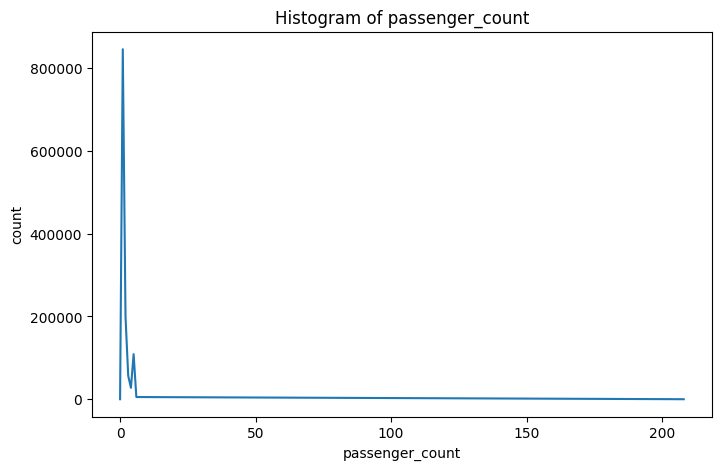

Column trip_distance


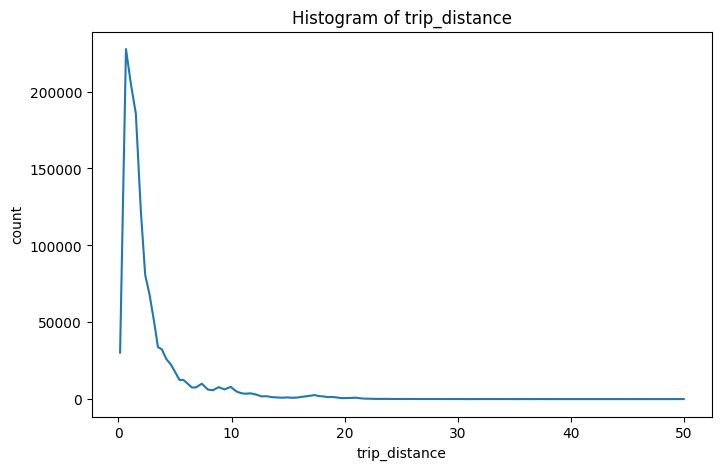

Column rate_code_id


Problem at column rate_code_id - 'NoneType' object is not iterable
Column pickup_longitude


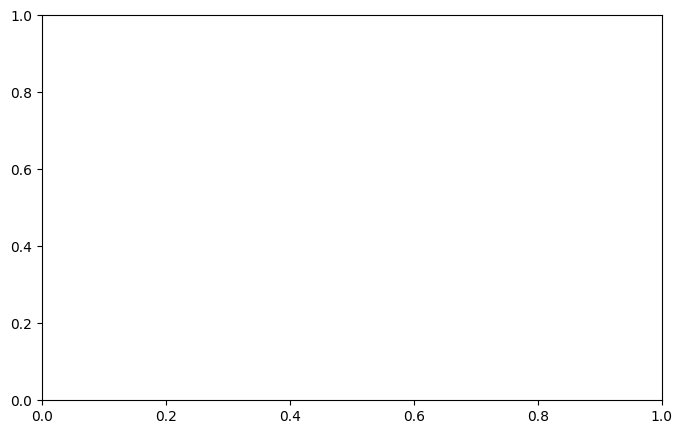

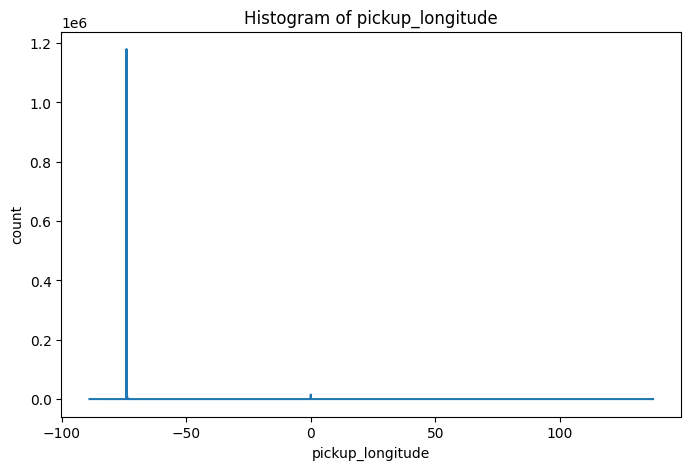

Column pickup_latitude


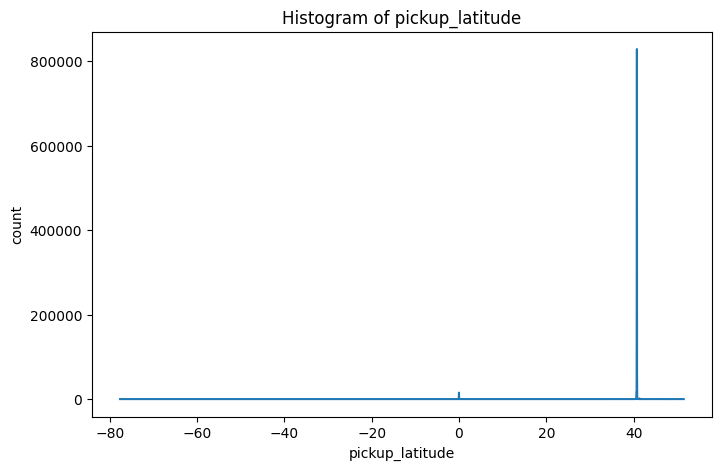

Column dropoff_longitude


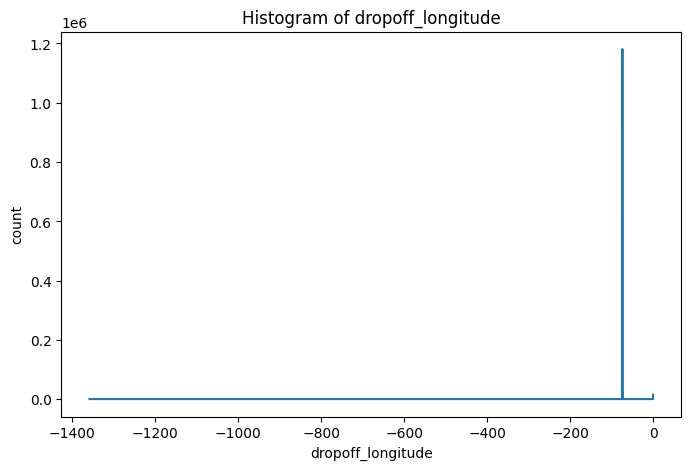

Column dropoff_latitude


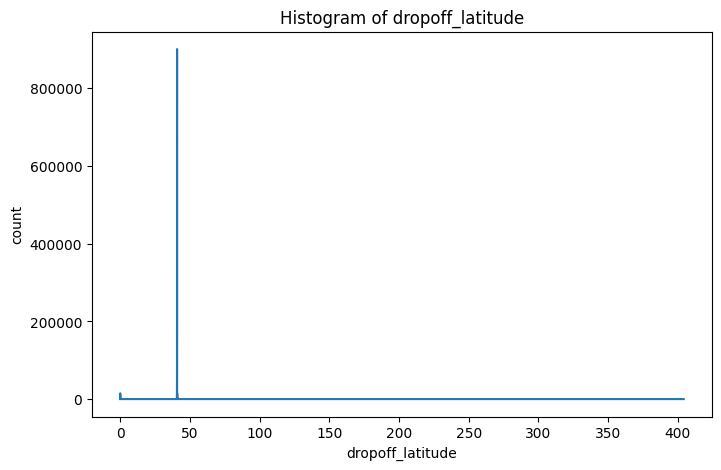

Column fare_amount


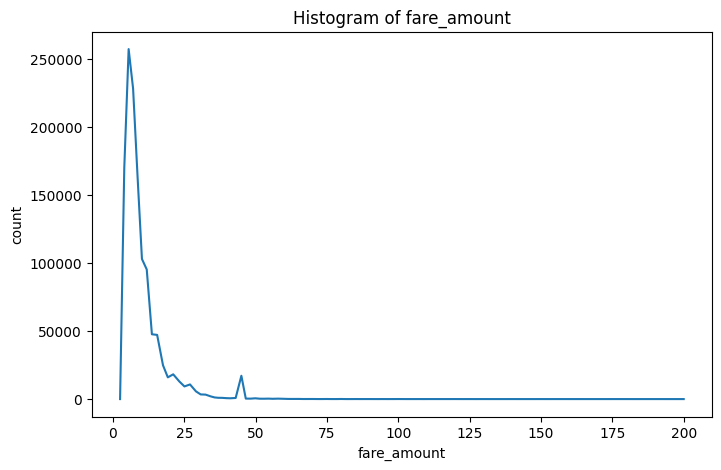

Column extra


Problem at column extra - 'NoneType' object is not iterable
Column mta_tax


Problem at column mta_tax - 'NoneType' object is not iterable
Column surcharge


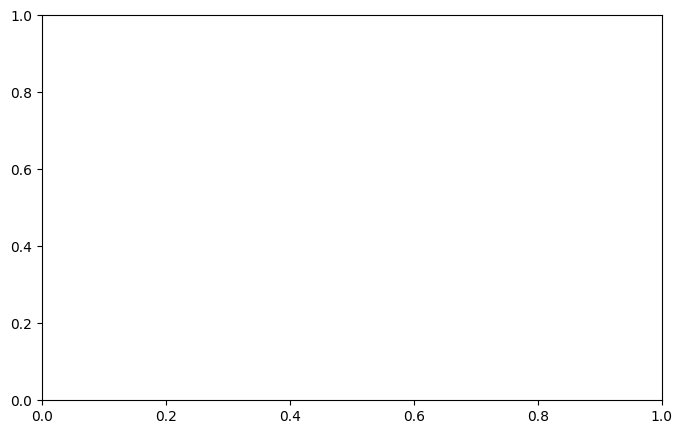

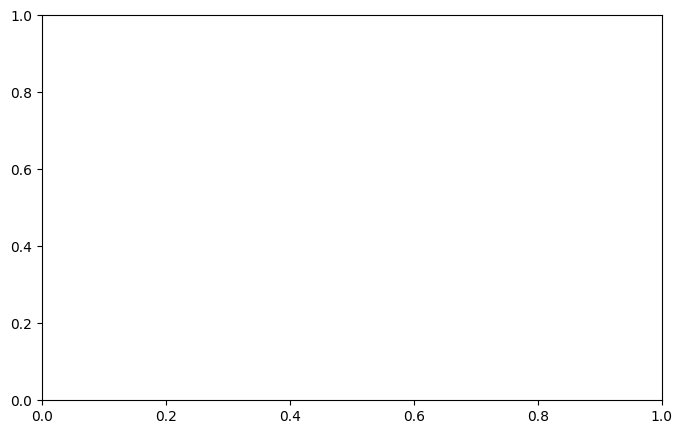

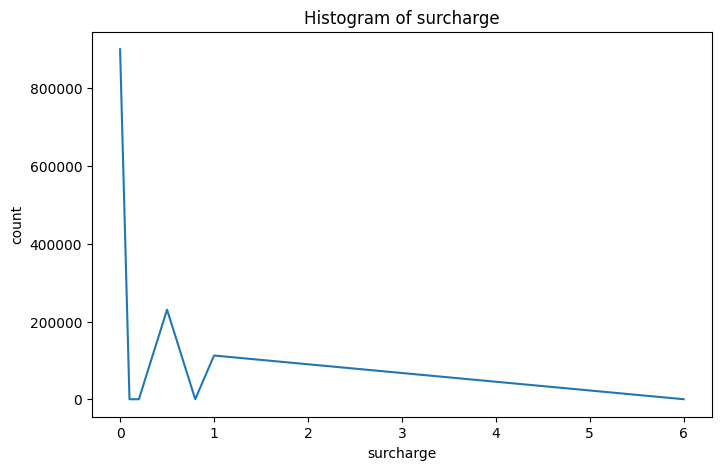

Column improvement_surcharge


Problem at column improvement_surcharge - 'NoneType' object is not iterable
Column tip_amount


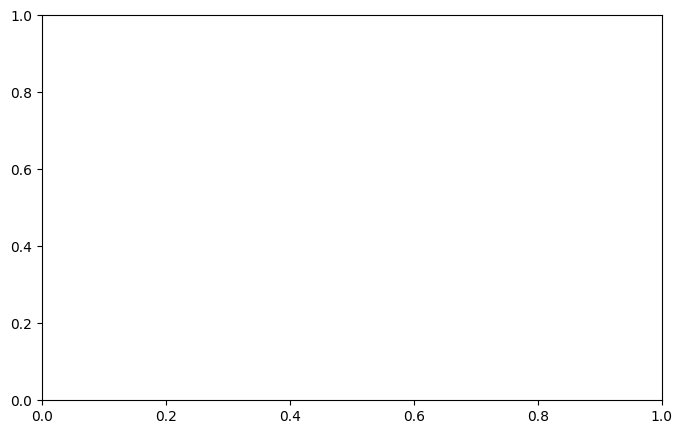

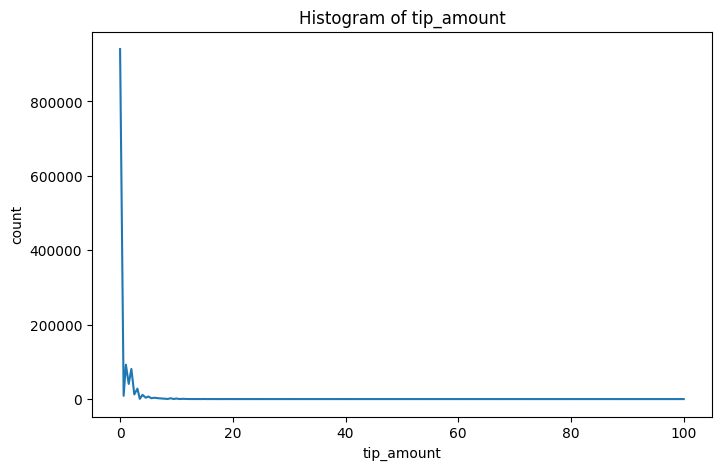

Column tolls_amount


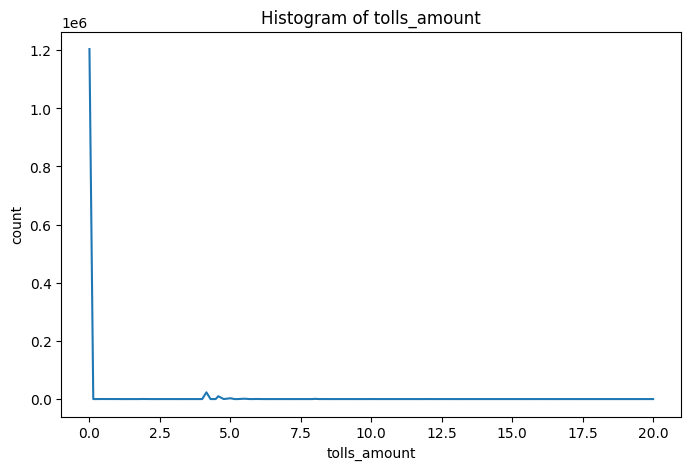

Column total_amount


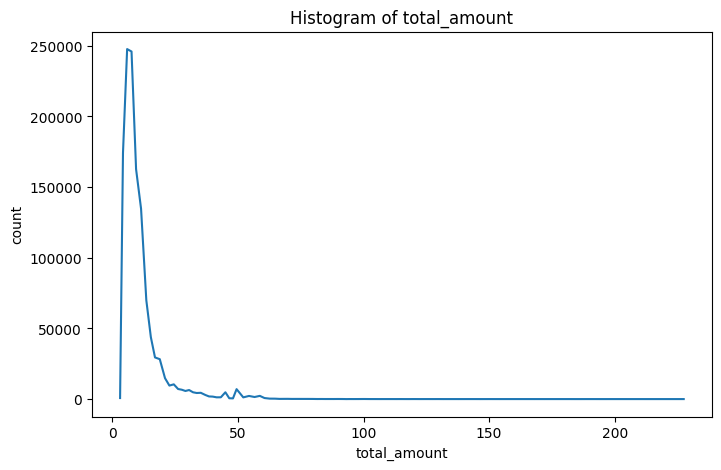

Column congestion_surcharge


Problem at column congestion_surcharge - 'NoneType' object is not iterable
Column airport_fee


Problem at column airport_fee - 'NoneType' object is not iterable
Column cbd_congestion_fee


Problem at column cbd_congestion_fee - 'NoneType' object is not iterable


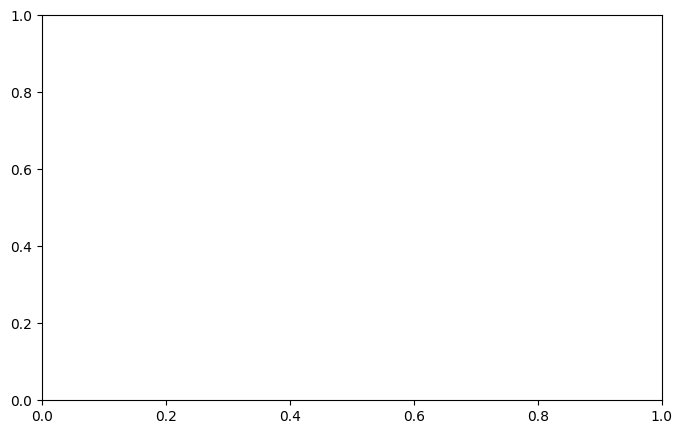

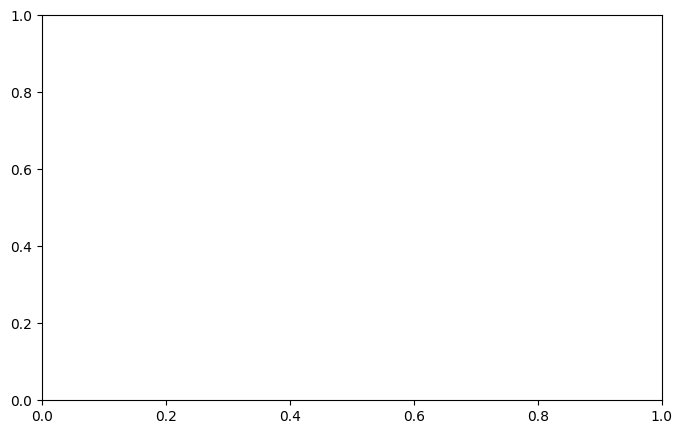

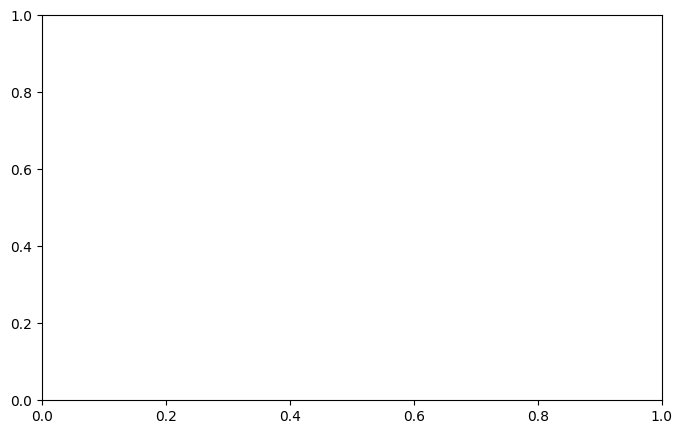

In [ ]:
def draw_distribution(df:DataFrame, col:str, bins:int):
    plt.figure(figsize=(8,5))
    plt.xticks(rotation=0)

    col_dtype = df.dtypes[df.columns.index(col)][1]
    if col_dtype=='int' or col_dtype=='double':
        print(f'Column {col}')
        pd_df = df_paymentType.select(F.histogram_numeric(col, F.lit(bins))).toPandas()
        try:
            X = [a[0] for a in pd_df.iloc[0,0]]
            Y = [a[1] for a in pd_df.iloc[0,0]]
            plt.plot(X, Y)
            plt.xlabel(col)
            plt.ylabel('count')
            plt.title(f'Histogram of {col}')
            plt.show()
        except Exception as e:
            print(f'Problem at column {col} - {e}')

for col in numeric_cols:
    draw_distribution(df_paymentType, col, 100)

## Các dữ liệu cần transform khi sang Silver

- Cast lại kiểu dữ liệu của một số cột (cast sang int)
- Thay giá trị trong một số cột (đổi từ ID sang giá trị cụ thể)